# Speed Dating Match Prediction — Audited Dual-Branch Transformer (corrected copy)

**This is a corrected COPY. Keep your original notebook untouched.** Each cell header says how it relates to the original:
`[UNCHANGED]`, `[REPLACES original Cell N]`, `[NEW]` or `[OPTIONAL]`.

## What this notebook does and does not claim
* **Task actually supported by the default feature set:** *post-encounter* prediction of mutual match (`match = dec & dec_o`) for a **new date between people who may already appear in the training data** (pair-disjoint evaluation). Subject/partner scorecard ratings (`attr, sinc, intel, fun, amb, shar, like, prob` and their `_o` versions) are recorded **during/after** the date, so they are not available for a pre-date matchmaker.
* A **pre-encounter** feature set, a **post-encounter-own-ratings** set and a **wave-disjoint (unseen-participant)** protocol are provided as *separate* experiments (see the grid cell). Which one a paper may cite is decided by what was run and measured, not by this text.
* No metric in this notebook has been pre-filled. Numbers appear only after you run it.

## Change log vs. the original (details in the audit report)
| Original cell | Status | Change |
|---|---|---|
| 2 | replaced | stronger seeding, extra imports, optional op-determinism |
| 8 | replaced | integer `pair_id`; integrity assertions; diagnostics (rating range, static-profile check, preference scale by wave, `age_o` vs partner age); `age_o` removed from rating list |
| 10 | replaced | **BUG FIX:** `age_o` is no longer clipped to 1–10, `age_gap` now uses real partner age; medians computed after clipping, train-only; nominal codes imputed with an explicit *unknown* level; `samerace` filled from train mode, not forced 0; split logic wrapped in reusable functions (pair / wave) |
| 12 | replaced | explicit feature sets with timing classification + forbidden-column assertion |
| 14, 16 | replaced | participant-overlap report; scaling wrapped in `prepare_arrays` |
| 18 | replaced | **hardening only, not a confirmed bug:** encoder block gets explicit `build()` and explicit `training` propagation (in a Keras 3.15 test the original block already round-tripped exactly and applied dropout correctly; the reload warning in your log is only a warning) |
| 20 | replaced | epoch cap raised (original run stopped at the 30-epoch cap, best epoch 25); dropout/inference diagnostics |
| 22 | replaced | vectorised threshold scan, full 0.01–0.99 grid, tie handling, edge warning, validation-pair bootstrap of the threshold |
| 24, 26, 28, 30 | replaced | complete metric suite, pair-clustered bootstrap CIs, PR-AUC via average precision, calibration |
| 32 | replaced | same LSTM kept, **plus** prior / logistic regression / gradient boosting baselines; all thresholds validation-selected |
| NEW | added | repeated-split × multi-seed grid across feature sets and split protocols |
| 34, 36 | replaced | artifact now stores imputation statistics; save/load round-trip assertion |

### Step 1 — Imports and reproducibility  


In [6]:
import os, sys, json, pickle, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, brier_score_loss, log_loss, matthews_corrcoef,
    confusion_matrix, classification_report, balanced_accuracy_score,
    roc_curve, precision_recall_curve
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

SEED = 42
ENABLE_OP_DETERMINISM = False   # True => bit-reproducible GPU ops where TF supports it (slower; may raise for unsupported ops)

def set_global_seed(seed: int):
    """Seeds python, numpy and TensorFlow/Keras in one call. Call before building every model."""
    tf.keras.utils.set_random_seed(int(seed))

set_global_seed(SEED)
if ENABLE_OP_DETERMINISM:
    tf.config.experimental.enable_op_determinism()

gpus = tf.config.list_physical_devices("GPU")
print(f"Hardware: {'GPU x' + str(len(gpus)) if gpus else 'CPU'} | TensorFlow {tf.__version__} | pandas {pd.__version__} | sklearn {__import__('sklearn').__version__}")

Hardware: GPU x2 | TensorFlow 2.21.0 | pandas 2.3.3 | sklearn 1.6.1


### Step 2 — Load data 

In [7]:
DATA_FILE = "Speed Dating Data.csv"
if not os.path.exists(DATA_FILE):
    alt_paths = [
        "/kaggle/input/datasets/bhumikayadav2307/speed-dating-dataset-columbia-university/Speed Dating Data.csv"
    ]
    for p in alt_paths:
        if os.path.exists(p):
            DATA_FILE = p
            break

print(f"Loading dataset from: {DATA_FILE}")
df_raw = pd.read_csv(DATA_FILE, encoding="ISO-8859-1")
print(f"Raw dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

Loading dataset from: /kaggle/input/datasets/bhumikayadav2307/speed-dating-dataset-columbia-university/Speed Dating Data.csv
Raw dataset shape: 8378 rows, 195 columns


### Step 3 — Target distribution  

Missing values in critical identifier columns:
  match: 0
  iid (Subject ID): 0
  pid (Partner ID): 10

Class Distribution:
match
0    6998
1    1380
Name: count, dtype: int64
Positive Match Rate: 16.47% (approx 1 in 6 dates result in mutual match)


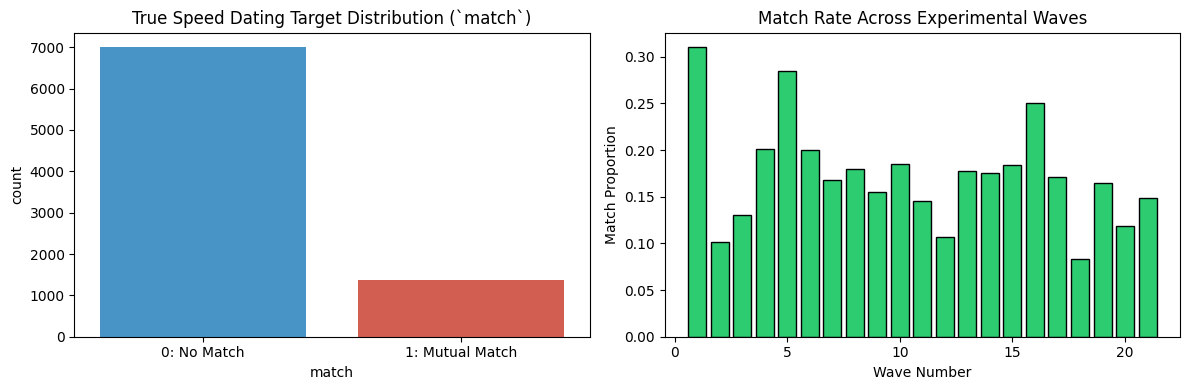

In [8]:
print("Missing values in critical identifier columns:")
print(f"  match: {df_raw['match'].isna().sum()}")
print(f"  iid (Subject ID): {df_raw['iid'].isna().sum()}")
print(f"  pid (Partner ID): {df_raw['pid'].isna().sum()}")

match_counts = df_raw['match'].value_counts()
print(f"\nClass Distribution:\n{match_counts}")
print(f"Positive Match Rate: {df_raw['match'].mean() * 100:.2f}% (approx 1 in 6 dates result in mutual match)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='match', data=df_raw, ax=axes[0], palette=['#3498db', '#e74c3c'], hue='match', legend=False)
axes[0].set_title("True Speed Dating Target Distribution (`match`)")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["0: No Match", "1: Mutual Match"])   # fixes the set_ticklabels warning

wave_match = df_raw.groupby('wave')['match'].mean()
axes[1].bar(wave_match.index, wave_match.values, color='#2ecc71', edgecolor='black')
axes[1].set_title("Match Rate Across Experimental Waves")
axes[1].set_xlabel("Wave Number")
axes[1].set_ylabel("Match Proportion")
plt.tight_layout()
plt.show()

### Step 4 — Clean, integrity checks, static participant profiles  `[REPLACES original Cell 8]`
Participant-profile aggregation here is **legitimate**: `groupby('iid').first()` collects each person's *own static* sign-up answers. It uses no label, no post-date rating and no statistic across people, so doing it before the split cannot leak the target. (It *would* leak if it aggregated `match`, scorecard ratings *received*, or any cross-participant statistic.) The diagnostics below check the assumption that these fields really are constant within a participant.

In [9]:
df_clean = df_raw.dropna(subset=["match", "iid", "pid"]).copy()
for c in ["iid", "pid", "match"]:
    df_clean[c] = df_clean[c].astype(int)
df_clean = df_clean.reset_index(drop=True)

# Integer key for the UNORDERED pair {iid, pid}: (A,B) and (B,A) share one key (original used a tuple; same grouping, safer type).
assert df_clean["iid"].max() < 10_000 and df_clean["pid"].max() < 10_000
df_clean["pair_id"] = (np.minimum(df_clean["iid"], df_clean["pid"]) * 10_000
                       + np.maximum(df_clean["iid"], df_clean["pid"])).astype(np.int64)

# ---- target / identifier integrity ----
assert set(df_clean["match"].unique()) <= {0, 1}, "match must be binary"
assert (df_clean["iid"] != df_clean["pid"]).all(), "self-dates found"
assert not df_clean.duplicated(["iid", "pid"]).any(), "duplicate (iid, pid) observations"
rows_per_pair = df_clean.groupby("pair_id").size()
print("Rows per unordered pair (expected: 2 = both directions recorded):", rows_per_pair.value_counts().to_dict())
assert df_clean.groupby("pair_id")["match"].nunique().max() == 1, "reciprocal rows disagree on `match`"
if {"dec", "dec_o"} <= set(df_clean.columns):
    ok = df_clean[["dec", "dec_o"]].notna().all(axis=1)
    mism = int(((df_clean.loc[ok, "dec"] * df_clean.loc[ok, "dec_o"]).astype(int) != df_clean.loc[ok, "match"]).sum())
    print(f"match != dec*dec_o in {mism} of {int(ok.sum())} rows with both decisions present (0 expected if `match` = mutual yes).")
print(f"Valid date interactions: {len(df_clean)} | unique unordered pairs: {df_clean['pair_id'].nunique()} | participants: {df_clean['iid'].nunique()}")

# ---- column groups (same as original, plus explicit groupings) ----
demog_cols = ["gender", "age", "field_cd", "career_c", "imprace", "imprelig", "date", "go_out"]
pref_cols = ["attr1_1", "sinc1_1", "intel1_1", "fun1_1", "amb1_1", "shar1_1"]
self_cols = ["attr3_1", "sinc3_1", "intel3_1", "fun3_1", "amb3_1"]
interest_cols = [
    "sports", "tvsports", "exercise", "dining", "museums", "art", "hiking",
    "gaming", "clubbing", "reading", "tv", "theater", "movies", "concerts",
    "music", "shopping", "yoga"
]
subj_rating_cols = ["attr", "sinc", "intel", "fun", "amb", "shar", "like", "prob"]
part_rating_cols = ["attr_o", "sinc_o", "intel_o", "fun_o", "amb_o", "shar_o", "like_o", "prob_o"]
profile_cols = demog_cols + pref_cols + self_cols + interest_cols
nominal_cols = ["field_cd", "career_c"]                    # categorical codes, NOT ordinal quantities

# 1-10 scorecard ratings ONLY. `age_o` (partner age, ~18-55) is deliberately NOT here: the original notebook put it in this
# list and then applied clip(1, 10) to it (see report, finding C1).
rating_cols_all = subj_rating_cols + part_rating_cols

# ---- diagnostics on the assumptions the preprocessing relies on ----
participant_profiles = df_clean.groupby("iid")[profile_cols].first()
varies = df_clean.groupby("iid")[profile_cols].nunique(dropna=True).max()
varies = varies[varies > 1]
print("Profile columns whose value changes within a participant (should be empty; .first() would hide it):", varies.to_dict())

print("\nRaw scorecard-rating range (values outside 1-10 will be clipped in Step 5):")
print(df_clean[rating_cols_all].agg(["min", "max"]).T.to_string())
n_out = int(((df_clean[rating_cols_all] < 1) | (df_clean[rating_cols_all] > 10)).sum().sum())
print("Out-of-range rating cells:", n_out)

partner_age_own = df_clean["pid"].map(participant_profiles["age"])
both = partner_age_own.notna() & df_clean["age_o"].notna()
print(f"\nage_o raw range: {df_clean['age_o'].min()}-{df_clean['age_o'].max()} | "
      f"age_o != partner's own `age` in {int((partner_age_own[both] != df_clean.loc[both, 'age_o']).sum())} of {int(both.sum())} comparable rows")

# Preference allocations (attr1_1 ... shar1_1) were collected on different scales across waves (100-point allocation vs 1-10 ratings).
wave_of = df_clean.groupby("iid")["wave"].first()
pref_sum = participant_profiles[pref_cols].sum(axis=1, skipna=False)
print("\nMedian sum of the six preference answers, by wave (a mix of ~100 and much smaller values means mixed scales):")
print(pref_sum.groupby(wave_of).median().round(1).to_dict())

# <<< NEW (2 diagnostics) >>>
print("Participants with >=1 missing preference answer (shares -> NaN -> train-median imputed in Step 5):",
      int(pref_sum.isna().sum()), "of", len(pref_sum))
print("\nRange of interest and self-rating profile columns (expected within 1-10):")
print(participant_profiles[interest_cols + self_cols].agg(["min", "max"]).T.to_string())
# <<< END NEW >>>

NORMALIZE_PREF_SCALE = True      # convert to within-person shares; scale-invariant, uses no labels and no fitted statistics
if NORMALIZE_PREF_SCALE:
    assert (pref_sum.dropna() > 0).all()
    participant_profiles[pref_cols] = participant_profiles[pref_cols].div(pref_sum, axis=0)

# ---- attach own and partner static profiles to every date row (no imputation here) ----
for col in profile_cols:
    df_clean[col] = df_clean["iid"].map(participant_profiles[col])
partner_profiles_df = pd.DataFrame(
    {f"{col}_partner": df_clean["pid"].map(participant_profiles[col]) for col in profile_cols}, index=df_clean.index)
df_clean = pd.concat([df_clean, partner_profiles_df], axis=1).copy()

df_base = df_clean.copy()    # pre-imputation snapshot; Step 5 always starts from this (so re-running Step 5 is safe)
print("\nCleaning & profile mapping complete. All imputation happens in Step 5, with statistics fitted on the TRAIN partition only.")

Rows per unordered pair (expected: 2 = both directions recorded): {2: 4184}
match != dec*dec_o in 0 of 8368 rows with both decisions present (0 expected if `match` = mutual yes).
Valid date interactions: 8368 | unique unordered pairs: 4184 | participants: 551
Profile columns whose value changes within a participant (should be empty; .first() would hide it): {}

Raw scorecard-rating range (values outside 1-10 will be clipped in Step 5):
         min   max
attr     0.0  10.0
sinc     0.0  10.0
intel    0.0  10.0
fun      0.0  10.0
amb      0.0  10.0
shar     0.0  10.0
like     0.0  10.0
prob     0.0  10.0
attr_o   0.0  10.5
sinc_o   0.0  10.0
intel_o  0.0  10.0
fun_o    0.0  11.0
amb_o    0.0  10.0
shar_o   0.0  10.0
like_o   0.0  10.0
prob_o   0.0  10.0
Out-of-range rating cells: 316

age_o raw range: 18.0-55.0 | age_o != partner's own `age` in 0 of 8274 comparable rows

Median sum of the six preference answers, by wave (a mix of ~100 and much smaller values means mixed scales):
{1: 100

### Step 5 — Splits, train-only imputation, feature engineering  
**Bug fixed here (confirmed):** the original put `age_o` in `rating_cols_all` and applied `clip(1, 10)`, so every observed partner age became **10**, while missing values were then filled with the *unclipped* training median (~26). `age_gap = |age - age_o|` therefore equalled roughly `age - 10` (or `age - 26` for missing `age_o`) instead of a gap between two people. Your recorded output (`age_gap` mean ≈ 16.2, min 0, max 45) is exactly what that logic produces.

Other changes: medians are computed **after** clipping and on training rows only; nominal codes (`field_cd`, `career_c`) get an explicit *unknown* level (`0`) instead of a fabricated median category; `samerace` is filled with the training mode rather than a hard-coded 0.

Two split protocols are available through `make_split_labels`:
* `"pair"` (default, same as the original): reciprocal rows stay together; **participants may recur** across train/val/test → "new date, possibly known people".
* `"wave"`: whole events are held out. Dates only occur within a wave, so this is **pair-disjoint and participant-disjoint with no discarded rows** → "unseen people".

In [11]:
partner_profile_cols = [f"{c}_partner" for c in profile_cols]
part_pref_cols = [f"{c}_partner" for c in pref_cols]
part_interest_cols = [f"{c}_partner" for c in interest_cols]

def make_split_labels(df, scheme="pair", seed=SEED, n_outer=5, n_inner=5):
    """Return an object array of 'train'/'val'/'test' for every row of `df`.
    Uses only `match` (for stratification) and the grouping column - no imputed value and no feature."""
    if scheme == "pair":
        groups = df["pair_id"].to_numpy()
    elif scheme == "wave":
        groups = df["wave"].astype(int).to_numpy()
    else:
        raise ValueError("scheme must be 'pair' or 'wave'")
    y = df["match"].to_numpy()
    outer = StratifiedGroupKFold(n_splits=n_outer, shuffle=True, random_state=seed)
    tv_idx, te_idx = next(outer.split(np.zeros(len(df)), y, groups))
    inner = StratifiedGroupKFold(n_splits=n_inner, shuffle=True, random_state=seed)
    tr_rel, va_rel = next(inner.split(np.zeros(len(tv_idx)), y[tv_idx], groups[tv_idx]))
    labels = np.full(len(df), "test", dtype=object)
    labels[tv_idx[tr_rel]] = "train"
    labels[tv_idx[va_rel]] = "val"
    return labels


def preprocess_and_engineer(df_in, profiles, split_labels):
    """Fit every learned preprocessing statistic on TRAIN rows only, apply to all rows, then engineer features.
    Returns (processed dataframe with a 'split' column, dict of fitted statistics)."""
    df = df_in.copy()
    df["split"] = split_labels
    is_train = (df["split"] == "train").to_numpy()
    train_iids = df.loc[is_train, "iid"].unique()

    # --- statistics fitted on training data only ---
    profile_medians = profiles.loc[profiles.index.isin(train_iids), profile_cols].median()
    for c in nominal_cols:
        profile_medians[c] = 0.0                      # explicit "unknown" level for nominal codes (valid codes start at 1)

    # Ratings outside 1-10 are invalid -> set to missing (NOT clipped). Medians come from VALID TRAIN values only.
    rating_raw = df[rating_cols_all].astype(float)
    ratings_valid = rating_raw.where(rating_raw.ge(1) & rating_raw.le(10))
    rating_medians = ratings_valid.loc[is_train].median()
    assert rating_medians.notna().all(), "a rating column has no valid training values"
    assert rating_medians.between(1, 10).all(), "a training rating median is outside 1-10"

    sr_mode = df.loc[is_train, "samerace"].mode()
    samerace_fill = float(sr_mode.iloc[0]) if len(sr_mode) else 0.0

    # --- apply ---
    df[profile_cols] = df[profile_cols].fillna(profile_medians[profile_cols].to_dict())
    df[partner_profile_cols] = df[partner_profile_cols].fillna(
        dict(zip(partner_profile_cols, profile_medians[profile_cols].to_numpy())))
    df[rating_cols_all] = ratings_valid.fillna(rating_medians.to_dict())
    assert df[rating_cols_all].isna().sum().sum() == 0, "missing rating values remain"
    assert df[rating_cols_all].ge(1).all().all() and df[rating_cols_all].le(10).all().all(), "out-of-range rating values remain"
    n_samerace_missing = int(df["samerace"].isna().sum())
    df["samerace"] = df["samerace"].fillna(samerace_fill)
    # NOTE: `age_o` is neither clipped nor used as a feature. Partner age enters through `age_partner` (static profile).

    # --- feature engineering (row-wise functions of already-cleaned inputs; nothing is fitted here) ---
    eng = {}
    pref_arr = df[pref_cols].to_numpy()
    subj_trait_arr = df[subj_rating_cols[:6]].to_numpy()
    eng["pref_alignment"] = ((pref_arr / (pref_arr.sum(axis=1, keepdims=True) + 1e-6)) * subj_trait_arr).sum(axis=1)
    eng["trait_composite"] = df[subj_rating_cols[:6]].mean(axis=1).to_numpy()
    eng["interest_vector_norm"] = np.linalg.norm(df[interest_cols].to_numpy(), axis=1)

    part_pref_arr = df[part_pref_cols].to_numpy()
    part_trait_arr = df[part_rating_cols[:6]].to_numpy()
    eng["pref_alignment_partner"] = ((part_pref_arr / (part_pref_arr.sum(axis=1, keepdims=True) + 1e-6)) * part_trait_arr).sum(axis=1)
    eng["trait_composite_partner"] = df[part_rating_cols[:6]].mean(axis=1).to_numpy()
    eng["interest_vector_norm_partner"] = np.linalg.norm(df[part_interest_cols].to_numpy(), axis=1)

    eng["age_gap"] = (df["age"] - df["age_partner"]).abs().to_numpy()       # FIXED: real partner age, not clipped age_o
    self_int = df[interest_cols].to_numpy()
    part_int = df[part_interest_cols].to_numpy()
    eng["shared_interest_sim"] = (self_int * part_int).sum(axis=1) / (
        np.linalg.norm(self_int, axis=1) * np.linalg.norm(part_int, axis=1) + 1e-6)
    df = pd.concat([df, pd.DataFrame(eng, index=df.index)], axis=1).copy()

    stats = dict(profile_medians=profile_medians.to_dict(), rating_medians=rating_medians.to_dict(),
                 samerace_fill=samerace_fill, n_samerace_missing=n_samerace_missing,
                 n_train_participants=int(len(train_iids)), n_participants=int(df["iid"].nunique()))
    return df, stats


# ---- primary protocol (same split family and seed as the original) ----
SPLIT_SCHEME = "pair"
split_labels = make_split_labels(df_base, SPLIT_SCHEME, SEED)
df_clean, imputation_stats = preprocess_and_engineer(df_base, participant_profiles, split_labels)

print(f"Rows per split: {df_clean['split'].value_counts().to_dict()}")
print(f"Participants contributing to the profile medians: {imputation_stats['n_train_participants']} of {imputation_stats['n_participants']}"
      "  (under the pair split nearly everyone has >=1 training row; under the 'wave' split this is a strict subset)")
print("`samerace` missing before fill:", imputation_stats["n_samerace_missing"])

# ---- verification of rating cleaning on every partition ----
for _s in ("train", "val", "test"):
    _r = df_clean.loc[df_clean["split"] == _s, rating_cols_all]
    assert _r.isna().sum().sum() == 0, f"missing rating values remain in {_s}"
    assert _r.ge(1).all().all() and _r.le(10).all().all(), f"out-of-range rating values remain in {_s}"

# ---- verification of the age fix ----
assert "age_o" not in rating_cols_all
assert df_base["age_o"].dropna().max() > 10, "age_o must keep its real (unclipped) values"
corr = np.corrcoef(df_clean["age_gap"], df_clean["age"])[0, 1]
print(f"corr(age_gap, age) = {corr:.3f}   (with the old bug this was ~1 because age_gap ~ age - 10)")
assert abs(corr) < 0.95
print(df_clean[["pref_alignment", "trait_composite", "age_gap", "shared_interest_sim"]].describe().T[["mean", "std", "min", "max"]])

# <<< NEW (engineered-feature range checks) >>>
assert df_clean["age_gap"].between(0, 60).all(), "age_gap outside 0-60"
assert df_clean["shared_interest_sim"].between(-1e-6, 1 + 1e-6).all(), "shared_interest_sim outside [0, 1]"
assert (df_clean[["pref_alignment", "pref_alignment_partner", "trait_composite", "trait_composite_partner"]].min() >= 0).all(), \
    "negative engineered score"
# <<< END NEW >>>

Rows per split: {'train': 5354, 'test': 1674, 'val': 1340}
Participants contributing to the profile medians: 551 of 551  (under the pair split nearly everyone has >=1 training row; under the 'wave' split this is a strict subset)
`samerace` missing before fill: 0
corr(age_gap, age) = 0.301   (with the old bug this was ~1 because age_gap ~ age - 10)
                         mean       std       min        max
pref_alignment       6.649106  1.369210  0.999999   9.999990
trait_composite      6.591946  1.327080  1.000000  10.000000
age_gap              3.652486  3.047009  0.000000  32.000000
shared_interest_sim  0.888969  0.056703  0.478136   0.989852


### Step 6 — Feature sets and their availability in time  
| Group | Examples | Timing | Pre-encounter model | Post-encounter, own ratings | Post-encounter, both ratings (= original features) |
|---|---|---|---|---|---|
| Static participant info (sign-up survey, suffix `_1`) | demographics, preference allocation, self-ratings, interests | before the event | ✔ | ✔ | ✔ |
| Dyadic static | `age_gap`, `samerace`, `shared_interest_sim` | before the date (derived from static info) | ✔ | ✔ | ✔ |
| Subject's own scorecard ratings | `attr…prob`, `pref_alignment`, `trait_composite` | **during/after** the date | ✘ | ✔ | ✔ |
| Partner's scorecard ratings of the subject | `attr_o…prob_o`, `pref_alignment_partner`, `trait_composite_partner` | **during/after** the date (revealed only later) | ✘ | ✘ | ✔ |
| Identifiers / target-derived (never inputs) | `iid, pid, pair_id, wave, match, dec, dec_o, match_es` | — | ✘ | ✘ | ✘ |

In [12]:
static_subj = demog_cols + pref_cols + self_cols + interest_cols + ["interest_vector_norm"]
static_part = ([f"{c}_partner" for c in demog_cols] + part_pref_cols + [f"{c}_partner" for c in self_cols]
               + part_interest_cols + ["interest_vector_norm_partner"])
own_rating_feats = subj_rating_cols + ["pref_alignment", "trait_composite"]
partner_rating_feats = part_rating_cols + ["pref_alignment_partner", "trait_composite_partner"]
cross_features = ["age_gap", "samerace", "shared_interest_sim"]

FEATURE_SETS = {
    "pre_encounter":     (static_subj,                     static_part,                          cross_features),
    "post_own_ratings":  (static_subj + own_rating_feats,  static_part,                          cross_features),
    "post_both_ratings": (static_subj + own_rating_feats,  static_part + partner_rating_feats,   cross_features),  # == original composition
}
ACTIVE_FEATURE_SET = "post_both_ratings"       # default reproduces the ORIGINAL feature composition (with the age_gap fix)

FORBIDDEN = {"match", "dec", "dec_o", "match_es", "iid", "pid", "id", "idg", "partner", "pair_id", "split", "wave", "order", "round",
             "position", "positin1", "condtn"}
for name, (s, p, c) in FEATURE_SETS.items():
    allf = s + p + c
    assert not (set(allf) & FORBIDDEN), f"{name}: forbidden column used as a feature: {set(allf) & FORBIDDEN}"
    assert len(allf) == len(set(allf)), f"{name}: duplicated feature"
    assert all(f in df_clean.columns for f in allf), f"{name}: missing columns"
    assert df_clean[allf].isna().sum().sum() == 0, f"{name}: NaNs remain"
    print(f"{name:18s} subject={len(s):3d} partner={len(p):3d} cross={len(c)}  total={len(allf)}")

subject_features, partner_features, cross_features = FEATURE_SETS[ACTIVE_FEATURE_SET]
# <<< CHANGED: the 47/47/3 check only applies to the set that reproduces the original composition >>>
if ACTIVE_FEATURE_SET == "post_both_ratings":
    assert len(subject_features) == 47 and len(partner_features) == 47 and len(cross_features) == 3
print(f"\nActive feature set: {ACTIVE_FEATURE_SET}")

pre_encounter      subject= 37 partner= 37 cross=3  total=77
post_own_ratings   subject= 47 partner= 37 cross=3  total=87
post_both_ratings  subject= 47 partner= 47 cross=3  total=97

Active feature set: post_both_ratings


### Step 7 — Materialise partitions and audit what the split guarantees  

In [13]:
def materialize(df):
    return {s: df[df["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}

parts_ = materialize(df_clean)
df_train, df_val, df_test = parts_["train"], parts_["val"], parts_["test"]
for name, d in parts_.items():
    print(f"{name:5s}: {len(d):5d} dates | {d['pair_id'].nunique():4d} pairs | {d['iid'].nunique():4d} participants | match rate {d['match'].mean()*100:.2f}% | positive pairs {int(d.groupby('pair_id')['match'].max().sum())}")

# ---- pair-level guarantee (what the split is designed to give) ----
pairs = {k: set(v["pair_id"]) for k, v in parts_.items()}
assert not (pairs["train"] & pairs["val"] or pairs["train"] & pairs["test"] or pairs["val"] & pairs["test"]), "pair overlap!"
assert df_clean.groupby("pair_id")["split"].nunique().max() == 1, "a pair crosses partitions"
print("\nPair-disjoint: every unordered pair (both reciprocal rows) lies in exactly one partition.")

# ---- participant overlap (what it does NOT guarantee) ----
ppl = {k: set(v["iid"]) for k, v in parts_.items()}
print(f"Participants in BOTH train and test: {len(ppl['train'] & ppl['test'])} of {len(ppl['test'])} test participants")
print(f"Participants in BOTH train and val : {len(ppl['train'] & ppl['val'])} of {len(ppl['val'])} validation participants")
if SPLIT_SCHEME == "wave":
    assert not (ppl["train"] & ppl["val"] or ppl["train"] & ppl["test"] or ppl["val"] & ppl["test"]), "participant overlap under wave split"
    print("Wave split: participant-disjoint as well.")
else:
    print("Pair split: participant overlap is EXPECTED. Results answer 'new date between people possibly seen before', "
          "not 'unseen people'. Use the wave protocol (grid cell) for the latter.")

train:  5354 dates | 2677 pairs |  551 participants | match rate 17.07% | positive pairs 457
val  :  1340 dates |  670 pairs |  519 participants | match rate 15.97% | positive pairs 107
test :  1674 dates |  837 pairs |  516 participants | match rate 15.05% | positive pairs 126

Pair-disjoint: every unordered pair (both reciprocal rows) lies in exactly one partition.
Participants in BOTH train and test: 516 of 516 test participants
Participants in BOTH train and val : 519 of 519 validation participants
Pair split: participant overlap is EXPECTED. Results answer 'new date between people possibly seen before', not 'unseen people'. Use the wave protocol (grid cell) for the latter.


### Step 8 — Scaling and class weights, fitted on training data only  

In [14]:
def prepare_arrays(df, subj_f, part_f, cross_f):
    """Scale each branch with a StandardScaler fitted on TRAIN rows only; return arrays for all partitions."""
    parts = materialize(df)
    scalers = {k: StandardScaler().fit(parts["train"][cols]) for k, cols in (("subj", subj_f), ("part", part_f), ("cross", cross_f))}
    out = {"scalers": scalers, "features": (list(subj_f), list(part_f), list(cross_f))}
    for s, d in parts.items():
        out[s] = {
            "X": [scalers["subj"].transform(d[subj_f]).astype("float32"),
                  scalers["part"].transform(d[part_f]).astype("float32"),
                  scalers["cross"].transform(d[cross_f]).astype("float32")],
            "y": d["match"].to_numpy().astype("float32"),
            "pair_id": d["pair_id"].to_numpy(),
        }
    ytr = out["train"]["y"]
    n_pos, n_neg = float((ytr == 1).sum()), float((ytr == 0).sum())
    out["class_weights"] = {0: len(ytr) / (2.0 * n_neg), 1: len(ytr) / (2.0 * n_pos)}   # from TRAIN labels only
    return out

data = prepare_arrays(df_clean, subject_features, partner_features, cross_features)
scaler_subj, scaler_part, scaler_cross = data["scalers"]["subj"], data["scalers"]["part"], data["scalers"]["cross"]
X_subj_train, X_part_train, X_cross_train = data["train"]["X"]
X_subj_val,   X_part_val,   X_cross_val   = data["val"]["X"]
X_subj_test,  X_part_test,  X_cross_test  = data["test"]["X"]
y_train, y_val, y_test = data["train"]["y"], data["val"]["y"], data["test"]["y"]
class_weights = data["class_weights"]
print(f"Class weights (from train labels): {class_weights}")
assert abs(float(X_subj_train.mean())) < 1e-3, "train features should be ~zero-mean after scaling"
for k in ("train", "val", "test"):
    assert data[k]["X"][0].shape[0] == len(data[k]["y"]) and data[k]["X"][0].shape[1] == len(subject_features)

Class weights (from train labels): {0: 0.6029279279279279, 1: 2.928884026258206}


### Step 9 — Dual-branch Transformer  
Architecture, loss and optimiser settings are **unchanged**. Two *hardening* edits to `TransformerEncoderBlock` (not confirmed bugs): an explicit `build()` so sublayers exist before weights are restored, and explicit `training` propagation. The original run printed Keras `build()` warnings on reload; whether they were benign is documented in the audit report. The original notebook never *checked* the round trip; Step 19 now asserts it on your environment.
Design note: the model uses mean-pooling over feature tokens rather than a `[CLS]` token, so it is a feature-tokenised Transformer, not the exact FT-Transformer recipe. Each token has its own learned weight and bias, which is what tells features apart (no positional encoding is needed or used).

In [15]:
class FeatureTokenizer(layers.Layer):
    """Projects each tabular feature value into a learned d-dimensional token embedding. (UNCHANGED)"""
    def __init__(self, num_features, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_features = num_features
        self.embed_dim = embed_dim

    def build(self, input_shape):
        self.weight = self.add_weight(shape=(1, self.num_features, self.embed_dim), initializer="glorot_uniform",
                                      trainable=True, name="feat_weights")
        self.bias = self.add_weight(shape=(1, self.num_features, self.embed_dim), initializer="zeros",
                                    trainable=True, name="feat_biases")

    def call(self, x):
        return tf.expand_dims(x, -1) * self.weight + self.bias

    def get_config(self):
        config = super().get_config()
        config.update({"num_features": self.num_features, "embed_dim": self.embed_dim})
        return config


class TransformerEncoderBlock(layers.Layer):
    """Multi-head self-attention + LayerNorm + FeedForward + residuals (post-LN)."""
    def __init__(self, embed_dim, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim, self.num_heads, self.ff_dim, self.dropout_rate = embed_dim, num_heads, ff_dim, dropout_rate
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads)
        self.ffn = models.Sequential([layers.Dense(ff_dim, activation="gelu"), layers.Dropout(dropout_rate), layers.Dense(embed_dim)])
        self.ln1 = layers.LayerNormalization(epsilon=1e-5)
        self.ln2 = layers.LayerNormalization(epsilon=1e-5)
        self.drop1 = layers.Dropout(dropout_rate)
        self.drop2 = layers.Dropout(dropout_rate)

    def build(self, input_shape):                      # NEW: build sublayers explicitly so (de)serialisation restores their weights
        self.mha.build(query_shape=input_shape, value_shape=input_shape)
        self.ffn.build(input_shape)
        self.ln1.build(input_shape)
        self.ln2.build(input_shape)
        super().build(input_shape)

    def call(self, x, training=None):
        attn = self.drop1(self.mha(x, x, training=training), training=training)
        x = self.ln1(x + attn)
        ffn_out = self.drop2(self.ffn(x, training=training), training=training)
        return self.ln2(x + ffn_out)

    def get_config(self):
        config = super().get_config()
        config.update({"embed_dim": self.embed_dim, "num_heads": self.num_heads, "ff_dim": self.ff_dim, "dropout_rate": self.dropout_rate})
        return config


def build_dual_transformer(n_subj, n_part, n_cross, embed_dim=32, num_heads=4, ff_dim=64, dropout_rate=0.15,
                           learning_rate=3e-4, weight_decay=1e-4, seed=None):
    if seed is not None:
        set_global_seed(seed)
    in_subj = layers.Input(shape=(n_subj,), name="subject_input")
    in_part = layers.Input(shape=(n_part,), name="partner_input")
    in_cross = layers.Input(shape=(n_cross,), name="cross_input")

    tok_s = FeatureTokenizer(n_subj, embed_dim, name="subj_tokenizer")(in_subj)
    tok_p = FeatureTokenizer(n_part, embed_dim, name="part_tokenizer")(in_part)

    enc_s = TransformerEncoderBlock(embed_dim, num_heads, ff_dim, dropout_rate, name="subj_enc_1")(tok_s)
    enc_s = TransformerEncoderBlock(embed_dim, num_heads, ff_dim, dropout_rate, name="subj_enc_2")(enc_s)
    enc_p = TransformerEncoderBlock(embed_dim, num_heads, ff_dim, dropout_rate, name="part_enc_1")(tok_p)
    enc_p = TransformerEncoderBlock(embed_dim, num_heads, ff_dim, dropout_rate, name="part_enc_2")(enc_p)

    cross_sp = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads, name="cross_s_to_p")(query=enc_s, value=enc_p, key=enc_p)
    cross_ps = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads, name="cross_p_to_s")(query=enc_p, value=enc_s, key=enc_s)
    s_out = layers.LayerNormalization(epsilon=1e-5)(enc_s + cross_sp)
    p_out = layers.LayerNormalization(epsilon=1e-5)(enc_p + cross_ps)

    s_rep = layers.GlobalAveragePooling1D(name="subj_pool")(s_out)
    p_rep = layers.GlobalAveragePooling1D(name="part_pool")(p_out)

    merged = layers.Concatenate(name="merge_dyadic")([s_rep, p_rep, in_cross])
    x = layers.Dense(64, activation="gelu")(merged)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(32, activation="gelu")(x)
    out = layers.Dense(1, activation="sigmoid", name="match_probability")(x)

    model = models.Model(inputs=[in_subj, in_part, in_cross], outputs=out, name="Dual_Transformer_Matchmaker")
    model.compile(optimizer=optimizers.AdamW(learning_rate=learning_rate, weight_decay=weight_decay, clipnorm=1.0),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

transformer_model = build_dual_transformer(len(subject_features), len(partner_features), len(cross_features), seed=SEED)
transformer_model.summary()

Model: "Dual_Transformer_Matchmaker"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ subject_input       │ (None, 47)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ partner_input       │ (None, 47)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subj_tokenizer      │ (None, 47, 32)    │      3,008 │ subject_input[0]… │
│ (FeatureTokenizer)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ part_tokenizer      │ (None, 47, 32)    │      3,008 │ partner_input[0]… │
│ (FeatureTokenizer)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subj_enc_1          │ (None, 47, 32)    │      8,544 │ subj_tokenizer[0… │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ part_enc_1          │ (None, 47, 32)    │      8,544 │ part_tokenizer[0… │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subj_enc_2          │ (None, 47, 32)    │      8,544 │ subj_enc_1[0][0]  │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ part_enc_2          │ (None, 47, 32)    │      8,544 │ part_enc_1[0][0]  │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_s_to_p        │ (None, 47, 32)    │      4,224 │ part_enc_2[0][0], │
│ (MultiHeadAttentio… │                   │            │ subj_enc_2[0][0], │
│                     │                   │            │ part_enc_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_p_to_s        │ (None, 47, 32)    │      4,224 │ subj_enc_2[0][0], │
│ (MultiHeadAttentio… │                   │            │ part_enc_2[0][0], │
│                     │                   │            │ subj_enc_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 47, 32)    │          0 │ subj_enc_2[0][0], │
│                     │                   │            │ cross_s_to_p[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 47, 32)    │          0 │ part_enc_2[0][0], │
│                     │                   │            │ cross_p_to_s[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 47, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 47, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subj_pool           │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ part_pool           │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 55,233 (215.75 KB)

 Trainable params: 55,233 (215.75 KB)

 Non-trainable params: 0 (0.00 B)

### Step 10 — Train (validation-based early stopping)  
Only the **epoch cap** changes (30 → 100); see the audit report for why. The cell below prints whether training stopped by early stopping or by the cap. Checkpoint selection uses **validation AUC only**; the test partition is not touched here.
Note on the curves: `loss` during training is class-weighted and measured with dropout on; `val_loss` is unweighted and measured with dropout off, so the two are not directly comparable.

In [16]:
MAX_EPOCHS = 100

def make_callbacks(verbose=1):
    return [
        callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True, verbose=verbose),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=verbose),
    ]

def fit_transformer(d, seed, epochs=None, batch_size=64, verbose=0, **arch_kwargs):
    """Train on d['train'], early-stop/checkpoint on d['val']. Never reads d['test']."""
    epochs = MAX_EPOCHS if epochs is None else epochs
    Xs, Xp, Xc = d["train"]["X"]
    model = build_dual_transformer(Xs.shape[1], Xp.shape[1], Xc.shape[1], seed=seed, **arch_kwargs)
    hist = model.fit(d["train"]["X"], d["train"]["y"], validation_data=(d["val"]["X"], d["val"]["y"]),
                     class_weight=d["class_weights"], epochs=epochs, batch_size=batch_size,
                     callbacks=make_callbacks(verbose=1 if verbose else 0), verbose=verbose)
    return model, hist

transformer_model, history_trans = fit_transformer(data, seed=SEED, verbose=2)
n_run = len(history_trans.history["loss"]); best_ep = int(np.argmax(history_trans.history["val_auc"])) + 1
print(f"\nEpochs run: {n_run} (cap {MAX_EPOCHS}) | best validation-AUC epoch: {best_ep} | stopped by early stopping: {n_run < MAX_EPOCHS}")

# ---- diagnostics: dropout is active only in training mode; inference is deterministic ----
xs = [a[:64] for a in data["val"]["X"]]
a1, a2 = (transformer_model(xs, training=True).numpy() for _ in range(2))
b1, b2 = (transformer_model(xs, training=False).numpy() for _ in range(2))
assert not np.allclose(a1, a2), "dropout appears inactive in training mode"
assert np.allclose(b1, b2), "inference is not deterministic"
print("Diagnostics passed: dropout active when training=True, deterministic when training=False.")

Epoch 1/100
84/84 - 59s - 702ms/step - accuracy: 0.6754 - auc: 0.7642 - loss: 0.5874 - val_accuracy: 0.7216 - val_auc: 0.8255 - val_loss: 0.5319 - learning_rate: 3.0000e-04
Epoch 2/100
84/84 - 1s - 13ms/step - accuracy: 0.7592 - auc: 0.8462 - loss: 0.4872 - val_accuracy: 0.7403 - val_auc: 0.8418 - val_loss: 0.5171 - learning_rate: 3.0000e-04
Epoch 3/100
84/84 - 1s - 11ms/step - accuracy: 0.7734 - auc: 0.8625 - loss: 0.4618 - val_accuracy: 0.7575 - val_auc: 0.8510 - val_loss: 0.5038 - learning_rate: 3.0000e-04
Epoch 4/100
84/84 - 1s - 11ms/step - accuracy: 0.7807 - auc: 0.8714 - loss: 0.4482 - val_accuracy: 0.7806 - val_auc: 0.8581 - val_loss: 0.4608 - learning_rate: 3.0000e-04
Epoch 5/100
84/84 - 1s - 11ms/step - accuracy: 0.7906 - auc: 0.8804 - loss: 0.4316 - val_accuracy: 0.7769 - val_auc: 0.8630 - val_loss: 0.4599 - learning_rate: 3.0000e-04
Epoch 6/100
84/84 - 1s - 11ms/step - accuracy: 0.7893 - auc: 0.8835 - loss: 0.4275 - val_accuracy: 0.7836 - val_auc: 0.8674 - val_loss: 0.4458 

### Step 11 — Decision threshold from validation data only  
Changes: grid widened to 0.01–0.99 (the original 0.10–0.90 could clip the optimum for differently calibrated models), ties resolved by the **median of all maximisers**, a warning is raised if the optimum sits on a grid edge, and the scan is vectorised (checked against scikit-learn below). Note the class-weighted loss shifts probabilities upward, so the optimal threshold is expected to be well above 0.5 and the outputs are **scores, not calibrated probabilities** (see Step 12 calibration metrics).

Selected threshold (validation macro-F1): 0.71 | validation macro-F1 there: 0.7445
Thresholds within 0.005 of the best validation macro-F1: [0.68, 0.7, 0.71, 0.72, 0.73]
Validation-bootstrap threshold: median 0.72, 5-95% range 0.68-0.87


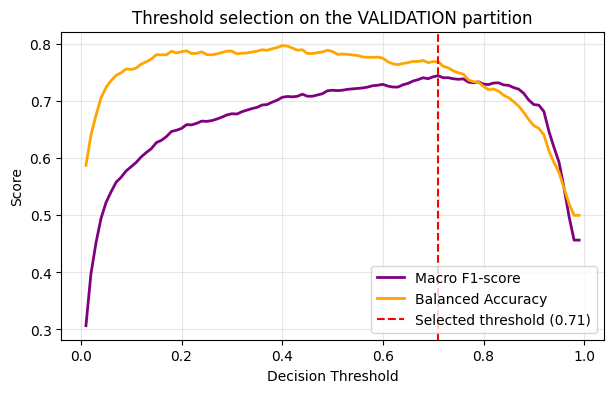

In [17]:
THRESH_GRID = np.linspace(0.01, 0.99, 99)

def threshold_scan(y, p, grid=THRESH_GRID):
    """Vectorised macro-F1 and balanced accuracy for every threshold in `grid` (positive class = 1, rule: p >= t)."""
    y1 = (np.asarray(y) == 1)[:, None]
    pred = np.asarray(p)[:, None] >= grid[None, :]
    tp = (pred & y1).sum(0); fp = (pred & ~y1).sum(0); fn = (~pred & y1).sum(0); tn = (~pred & ~y1).sum(0)
    f1_pos = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    f1_neg = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    macro_f1 = (f1_pos + f1_neg) / 2
    bal_acc = (tp / np.maximum(tp + fn, 1) + tn / np.maximum(tn + fp, 1)) / 2
    return macro_f1, bal_acc

def tune_decision_threshold(y_true, y_prob, grid=THRESH_GRID):
    """Returns (best_threshold, best_macro_f1, grid, macro_f1_curve, balanced_accuracy_curve). Uses ONLY the arrays passed in."""
    macro_f1, bal_acc = threshold_scan(y_true, y_prob, grid)
    best = macro_f1.max()
    tied = grid[np.isclose(macro_f1, best)]
    t = float(tied[np.argmin(np.abs(tied - np.median(tied)))])   # <<< CHANGED: nearest TIED grid point to the median, so F1 at t is the maximum
    if t <= grid[0] + 1e-9 or t >= grid[-1] - 1e-9:
        warnings.warn(f"Selected threshold {t:.2f} is on the grid boundary; the scan may be truncating the optimum.")
    return t, float(best), grid, macro_f1, bal_acc

# --- verification: vectorised scan equals scikit-learn on a few thresholds ---
_p = np.random.default_rng(0).random(500); _y = (np.random.default_rng(1).random(500) < 0.2).astype(int)
_mf, _ba = threshold_scan(_y, _p)
for _t in (0.05, 0.3, 0.55, 0.9):
    _i = int(np.argmin(np.abs(THRESH_GRID - _t))); _pred = (_p >= THRESH_GRID[_i]).astype(int)
    assert np.isclose(_mf[_i], f1_score(_y, _pred, average="macro", zero_division=0))
    assert np.isclose(_ba[_i], balanced_accuracy_score(_y, _pred))

prob_trans_val = transformer_model.predict(data["val"]["X"], verbose=0).ravel()
best_threshold, best_val_f1, thresh_range, f1_scores, bal_acc_scores = tune_decision_threshold(y_val, prob_trans_val)
print(f"Selected threshold (validation macro-F1): {best_threshold:.2f} | validation macro-F1 there: {best_val_f1:.4f}")
print(f"Thresholds within 0.005 of the best validation macro-F1: {thresh_range[f1_scores >= best_val_f1 - 0.005].round(2).tolist()}")

# --- how stable is the selected threshold? (bootstrap over validation PAIRS; validation data only) ---
rng = np.random.default_rng(0)
vp = data["val"]["pair_id"]; u, inv = np.unique(vp, return_inverse=True); idx_by = [np.where(inv == g)[0] for g in range(len(u))]
boot_t = []
for _ in range(200):
    ii = np.concatenate([idx_by[g] for g in rng.integers(0, len(u), len(u))])
    if y_val[ii].min() != y_val[ii].max():
        boot_t.append(tune_decision_threshold(y_val[ii], prob_trans_val[ii])[0])
print(f"Validation-bootstrap threshold: median {np.median(boot_t):.2f}, 5-95% range {np.percentile(boot_t,5):.2f}-{np.percentile(boot_t,95):.2f}")

plt.figure(figsize=(7, 4))
plt.plot(thresh_range, f1_scores, label="Macro F1-score", color="purple", lw=2)
plt.plot(thresh_range, bal_acc_scores, label="Balanced Accuracy", color="orange", lw=2)
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Selected threshold ({best_threshold:.2f})")
plt.xlabel("Decision Threshold"); plt.ylabel("Score"); plt.title("Threshold selection on the VALIDATION partition")
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

### Step 12 — Test-set evaluation (run once, after every decision above is frozen)  
* All metrics use **class 1 = match** as the positive class. PR-AUC is reported as **average precision** (the trapezoidal `auc(recall, precision)` used in the original Cell 30 is optimistic for PR curves).
* Calibration: Brier score and expected calibration error (10 equal-width bins). Because of class weighting the raw outputs are expected to be over-confident for the positive class.
* Each pair contributes **two** rows with the same label, so the effective test size is the number of **pairs**. Confidence intervals therefore come from a **pair-clustered bootstrap** (threshold held fixed at its validation-selected value).
* **Caveat on the intervals:** the bootstrap resamples pairs and ignores dependence between dates that share a participant (pair split) or a wave (wave split). Treat these intervals as lower bounds on uncertainty and report the across-split spread from Step 17 alongside them.

In [18]:
def expected_calibration_error(y, p, n_bins=10):
    y = np.asarray(y, dtype=float); p = np.asarray(p, dtype=float)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean()) for b in range(n_bins) if (idx == b).any()))

def evaluate_binary(y, p, thr):
    """Complete metric dictionary. Positive class = 1. Threshold rule: p >= thr."""
    y = np.asarray(y).astype(int); p = np.asarray(p, dtype=float); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(thr), "prevalence": float(y.mean()),
        "roc_auc": roc_auc_score(y, p), "pr_auc_ap": average_precision_score(y, p),
        "brier": brier_score_loss(y, p), "ece": expected_calibration_error(y, p),
        "log_loss": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1]),
        "accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0),
        "specificity": recall_score(y, pred, pos_label=0, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0), "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y, pred), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

CI_METRICS = ("roc_auc", "pr_auc_ap", "macro_f1", "balanced_acc", "f1", "precision", "recall", "brier")

def cluster_bootstrap_ci(y, p, thr, groups, n_boot=500, seed=0, metrics=CI_METRICS):
    """Percentile CI from resampling whole PAIRS (both reciprocal rows together). Threshold is fixed, not re-tuned."""
    rng = np.random.default_rng(seed)
    u, inv = np.unique(groups, return_inverse=True); idx_by = [np.where(inv == g)[0] for g in range(len(u))]
    draws = {m: [] for m in metrics}
    for _ in range(n_boot):
        ii = np.concatenate([idx_by[g] for g in rng.integers(0, len(u), len(u))])
        if y[ii].min() == y[ii].max():
            continue
        r = evaluate_binary(y[ii], p[ii], thr)
        for m in metrics: draws[m].append(r[m])
    return {m: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for m, v in draws.items()}

def print_report(title, res, ci=None):
    print(f"--- {title} ---")
    for k in ("roc_auc", "pr_auc_ap", "brier", "ece", "accuracy", "balanced_acc", "precision", "recall", "specificity", "f1", "macro_f1", "mcc"):
        s = f"{k:13s}: {res[k]:.4f}"
        if ci and k in ci: s += f"   95% pair-bootstrap CI [{ci[k][0]:.4f}, {ci[k][1]:.4f}]"
        print(s)
    print(f"confusion (tn, fp, fn, tp): {res['tn']}, {res['fp']}, {res['fn']}, {res['tp']} | threshold {res['threshold']:.2f} | test prevalence {res['prevalence']:.3f}")

# ---- single evaluation of the frozen model on the untouched test partition ----
prob_trans_test = transformer_model.predict(data["test"]["X"], verbose=0).ravel()
preds_trans_test = (prob_trans_test >= best_threshold).astype(int)
test_res_trans = evaluate_binary(y_test, prob_trans_test, best_threshold)
test_ci_trans = cluster_bootstrap_ci(y_test, prob_trans_test, best_threshold, data["test"]["pair_id"])
print_report(f"Dual-branch Transformer | feature set '{ACTIVE_FEATURE_SET}' | split '{SPLIT_SCHEME}'", test_res_trans, test_ci_trans)
print(f"\nTest pairs: {len(np.unique(data['test']['pair_id']))} | positive pairs: {int(pd.Series(y_test).groupby(data['test']['pair_id']).max().sum())}")

--- Dual-branch Transformer | feature set 'post_both_ratings' | split 'pair' ---
roc_auc      : 0.8457   95% pair-bootstrap CI [0.8120, 0.8809]
pr_auc_ap    : 0.5614   95% pair-bootstrap CI [0.4799, 0.6545]
brier        : 0.1455   95% pair-bootstrap CI [0.1286, 0.1619]
ece          : 0.1417
accuracy     : 0.8363
balanced_acc : 0.7469   95% pair-bootstrap CI [0.7054, 0.7908]
precision    : 0.4671   95% pair-bootstrap CI [0.3944, 0.5360]
recall       : 0.6190   95% pair-bootstrap CI [0.5369, 0.7063]
specificity  : 0.8748
f1           : 0.5324   95% pair-bootstrap CI [0.4682, 0.5926]
macro_f1     : 0.7166   95% pair-bootstrap CI [0.6805, 0.7514]
mcc          : 0.4419
confusion (tn, fp, fn, tp): 1244, 178, 96, 156 | threshold 0.71 | test prevalence 0.151

Test pairs: 837 | positive pairs: 126


### Step 13 — Classification report and confusion matrix  

Classification Report (Transformer on Test Set):
              precision    recall  f1-score   support

 0: No Match     0.9284    0.8748    0.9008      1422
    1: Match     0.4671    0.6190    0.5324       252

    accuracy                         0.8363      1674
   macro avg     0.6977    0.7469    0.7166      1674
weighted avg     0.8589    0.8363    0.8453      1674



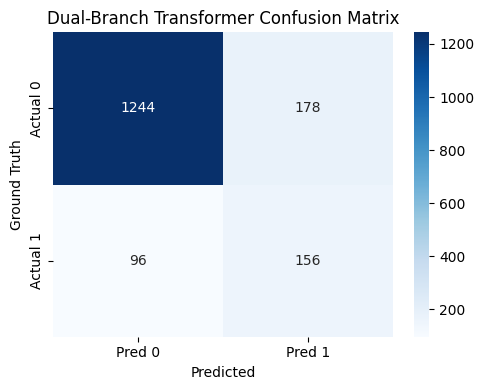

In [19]:
print("Classification Report (Transformer on Test Set):")
print(classification_report(y_test, preds_trans_test, target_names=["0: No Match", "1: Match"], digits=4))

cm_trans = confusion_matrix(y_test, preds_trans_test)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_trans, annot=True, fmt="d", cmap="Blues", xticklabels=["Pred 0", "Pred 1"], yticklabels=["Actual 0", "Actual 1"])
plt.title("Dual-Branch Transformer Confusion Matrix"); plt.ylabel("Ground Truth"); plt.xlabel("Predicted")
plt.tight_layout(); plt.show()

### Step 14 — Learning curves  

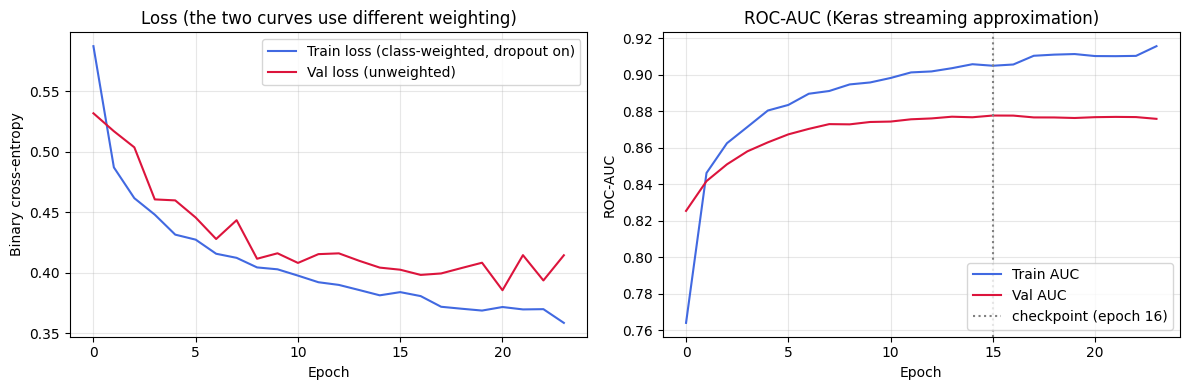

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_trans.history["loss"], label="Train loss (class-weighted, dropout on)", color="royalblue")
axes[0].plot(history_trans.history["val_loss"], label="Val loss (unweighted)", color="crimson")
axes[0].set_title("Loss (the two curves use different weighting)"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(history_trans.history["auc"], label="Train AUC", color="royalblue")
axes[1].plot(history_trans.history["val_auc"], label="Val AUC", color="crimson")
axes[1].axvline(best_ep - 1, color="gray", linestyle=":", label=f"checkpoint (epoch {best_ep})")
axes[1].set_title("ROC-AUC (Keras streaming approximation)"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("ROC-AUC")
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Step 15 — ROC, Precision–Recall and calibration curves  

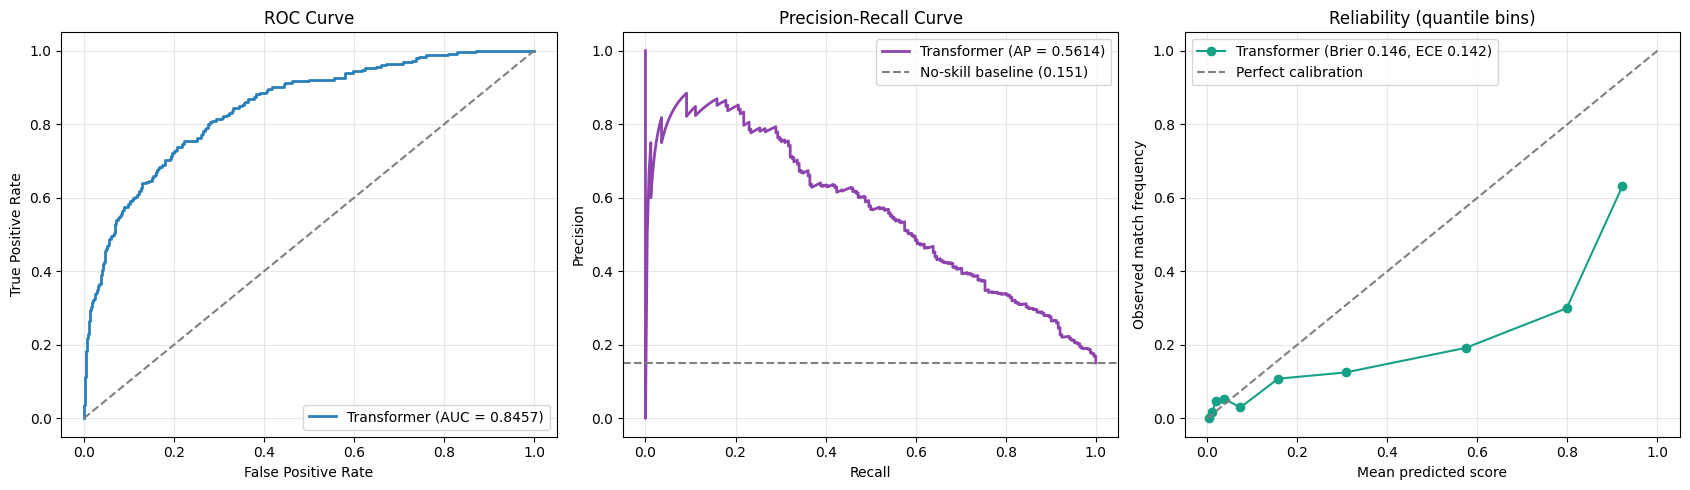

In [21]:
fpr, tpr, _ = roc_curve(y_test, prob_trans_test)
precs, recs, _ = precision_recall_curve(y_test, prob_trans_test)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(fpr, tpr, color="#2980b9", lw=2, label=f"Transformer (AUC = {test_res_trans['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--"); axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve"); axes[0].legend(loc="lower right"); axes[0].grid(True, alpha=0.3)

axes[1].plot(recs, precs, color="#8e44ad", lw=2, label=f"Transformer (AP = {test_res_trans['pr_auc_ap']:.4f})")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label=f"No-skill baseline ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall Curve"); axes[1].legend(loc="upper right"); axes[1].grid(True, alpha=0.3)

frac_pos, mean_pred = calibration_curve(y_test, prob_trans_test, n_bins=10, strategy="quantile")
axes[2].plot(mean_pred, frac_pos, "o-", color="#16a085", label=f"Transformer (Brier {test_res_trans['brier']:.3f}, ECE {test_res_trans['ece']:.3f})")
axes[2].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect calibration")
axes[2].set_xlabel("Mean predicted score"); axes[2].set_ylabel("Observed match frequency"); axes[2].set_title("Reliability (quantile bins)")
axes[2].legend(loc="upper left"); axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Step 16 — Baselines on the identical split  
The original LSTM baseline is **kept** (same architecture) and is now trained with the same epoch cap/callbacks as the Transformer. Added: a **prior/majority** model, **L2 logistic regression** (C chosen on validation AUC) and **histogram gradient boosting** (boosting rounds chosen on validation AUC; its internal random early-stopping split is disabled because it would split reciprocal pairs inside the training data). Thresholds for every model are selected on validation data only.
Caveats for interpretation: the LSTM reads an *unordered* feature list as if it were a sequence, so it is a weak architectural comparison; this section is one split and one seed — use the grid in Step 17 before concluding that any model is better.

In [22]:
def build_dual_lstm(n_subj, n_part, n_cross, hidden_lstm=32, seed=None):
    if seed is not None:
        set_global_seed(seed)
    in_subj = layers.Input(shape=(n_subj,), name="subj_input")
    in_part = layers.Input(shape=(n_part,), name="part_input")
    in_cross = layers.Input(shape=(n_cross,), name="cross_input")
    x_s = layers.Reshape((n_subj, 1))(in_subj)
    s = layers.LSTM(hidden_lstm * 2, return_sequences=True)(x_s); s = layers.Dropout(0.3)(s)
    s = layers.LSTM(hidden_lstm)(s); s = layers.BatchNormalization()(s)
    x_p = layers.Reshape((n_part, 1))(in_part)
    p = layers.LSTM(hidden_lstm * 2, return_sequences=True)(x_p); p = layers.Dropout(0.3)(p)
    p = layers.LSTM(hidden_lstm)(p); p = layers.BatchNormalization()(p)
    merged = layers.Concatenate()([s, p, in_cross])
    dense = layers.Dense(64, activation="relu")(merged); dense = layers.Dropout(0.3)(dense)
    dense = layers.Dense(32, activation="relu")(dense)
    out = layers.Dense(1, activation="sigmoid", name="match_probability")(dense)
    model = models.Model(inputs=[in_subj, in_part, in_cross], outputs=out, name="Dual_LSTM_Baseline")
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

def fit_lstm(d, seed):
    Xs, Xp, Xc = d["train"]["X"]
    m = build_dual_lstm(Xs.shape[1], Xp.shape[1], Xc.shape[1], seed=seed)
    m.fit(d["train"]["X"], d["train"]["y"], validation_data=(d["val"]["X"], d["val"]["y"]), class_weight=d["class_weights"],
          epochs=MAX_EPOCHS, batch_size=64, callbacks=make_callbacks(verbose=0), verbose=0)
    return m

def fit_logreg(d):
    Xtr, Xva, Xte = (np.hstack(d[k]["X"]) for k in ("train", "val", "test"))
    best = None
    for C in (0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0):
        m = LogisticRegression(C=C, class_weight="balanced", max_iter=5000).fit(Xtr, d["train"]["y"])
        auc_v = roc_auc_score(d["val"]["y"], m.predict_proba(Xva)[:, 1])
        if best is None or auc_v > best[0]: best = (auc_v, C, m)
    _, C, m = best
    return m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1], f"C={C}"

def fit_hgb(d, seed):
    Xtr, Xva, Xte = (np.hstack(d[k]["X"]) for k in ("train", "val", "test"))
    ytr = d["train"]["y"]; cw = d["class_weights"]
    sw = np.where(ytr == 1, cw[1], cw[0])
    m = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=15, min_samples_leaf=40,
                                       l2_regularization=1.0, early_stopping=False, random_state=seed)
    m.fit(Xtr, ytr, sample_weight=sw)
    val_stages = [p[:, 1] for p in m.staged_predict_proba(Xva)]
    k = int(np.argmax([roc_auc_score(d["val"]["y"], p) for p in val_stages]))       # boosting rounds chosen on VALIDATION AUC
    test_k = next(p[:, 1] for i, p in enumerate(m.staged_predict_proba(Xte)) if i == k)
    return val_stages[k], test_k, f"rounds={k+1}"

def collect_predictions(d, seed=SEED, names=("prior", "logreg", "hgb", "lstm"), pretrained=None):
    """Validation and test scores for each model. Test scores are produced but never used to choose anything."""
    out = {}
    for n in names:
        if n == "prior":
            c = float(d["train"]["y"].mean())
            out[n] = {"val": np.full(len(d["val"]["y"]), c), "test": np.full(len(d["test"]["y"]), c), "note": f"p={c:.3f}"}
        elif n == "logreg":
            pv, pt, note = fit_logreg(d); out[n] = {"val": pv, "test": pt, "note": note}
        elif n == "hgb":
            pv, pt, note = fit_hgb(d, seed); out[n] = {"val": pv, "test": pt, "note": note}
        elif n == "lstm":
            m = fit_lstm(d, seed); out[n] = {"val": m.predict(d["val"]["X"], verbose=0).ravel(), "test": m.predict(d["test"]["X"], verbose=0).ravel(), "note": ""}
        elif n == "transformer":
            if pretrained and "transformer" in pretrained: m = pretrained["transformer"]
            else: m, _ = fit_transformer(d, seed=seed)
            out[n] = {"val": m.predict(d["val"]["X"], verbose=0).ravel(), "test": m.predict(d["test"]["X"], verbose=0).ravel(), "note": ""}
    return out

TABLE_COLS = ["threshold", "val_roc_auc", "roc_auc", "pr_auc_ap", "brier", "ece", "macro_f1", "balanced_acc", "f1", "precision", "recall", "specificity", "accuracy"]

def comparison_table(preds, d):
    rows = []
    for name, pr in preds.items():
        thr = tune_decision_threshold(d["val"]["y"], pr["val"])[0]            # threshold from VALIDATION only
        r = evaluate_binary(d["test"]["y"], pr["test"], thr)
        r["val_roc_auc"] = roc_auc_score(d["val"]["y"], pr["val"]) if len(np.unique(pr["val"])) > 1 else 0.5
        rows.append({"model": name, **{k: r[k] for k in TABLE_COLS}, "note": pr.get("note", "")})
    return pd.DataFrame(rows).set_index("model")

preds_main = collect_predictions(data, SEED, names=("prior", "logreg", "hgb", "lstm", "transformer"), pretrained={"transformer": transformer_model})
comparison_main = comparison_table(preds_main, data)
print(f"Feature set '{ACTIVE_FEATURE_SET}' | split '{SPLIT_SCHEME}' | seed {SEED}  (single split, single seed: treat small gaps as noise)")
print(comparison_main.round(4).to_string())

Feature set 'post_both_ratings' | split 'pair' | seed 42  (single split, single seed: treat small gaps as noise)
             threshold  val_roc_auc  roc_auc  pr_auc_ap   brier     ece  macro_f1  balanced_acc      f1  precision  recall  specificity  accuracy        note
model                                                                                                                                                        
prior             0.58       0.5000   0.5000     0.1505  0.1283  0.0202    0.4593        0.5000  0.0000     0.0000  0.0000       1.0000    0.8495     p=0.171
logreg            0.62       0.8692   0.8132     0.4646  0.1711  0.2058    0.6797        0.7189  0.4792     0.4011  0.5952       0.8425    0.8053       C=1.0
hgb               0.60       0.8808   0.8399     0.5811  0.1114  0.1046    0.7447        0.7451  0.5663     0.5652  0.5675       0.9226    0.8692  rounds=366
lstm              0.70       0.8505   0.8006     0.4610  0.1726  0.2049    0.6880        0.7019  

### Step 17 — Save model, preprocessing statistics and run manifest 
The original artifact omitted the imputation statistics, so a deployed pipeline could not reproduce preprocessing. They are saved now.

In [23]:
# [REPLACES original Cell 34]
import hashlib                                                   # <<< NEW

model_save_path = "dual_transformer_matchmaker.keras"
transformer_model.save(model_save_path)
print(f"Saved Transformer model to: {model_save_path}")

scalers_payload = {
    "scaler_subj": scaler_subj, "scaler_part": scaler_part, "scaler_cross": scaler_cross,
    "best_threshold": float(best_threshold),
    "subject_features": subject_features, "partner_features": partner_features, "cross_features": cross_features,
    "feature_set": ACTIVE_FEATURE_SET, "split_scheme": SPLIT_SCHEME, "seed": SEED,
    "imputation_stats": imputation_stats, "normalize_pref_scale": NORMALIZE_PREF_SCALE, "class_weights": class_weights,
}
with open("speed_dating_scalers.pkl", "wb") as f:
    pickle.dump(scalers_payload, f)

manifest = {
    "seed": SEED, "split_scheme": SPLIT_SCHEME, "feature_set": ACTIVE_FEATURE_SET,
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                 "sklearn": __import__("sklearn").__version__, "tensorflow": tf.__version__},
    "rows": {k: int(len(v)) for k, v in parts_.items()}, "pairs": {k: int(v["pair_id"].nunique()) for k, v in parts_.items()},
    "participants": {k: int(v["iid"].nunique()) for k, v in parts_.items()},
    "class_weights": {str(k): float(v) for k, v in class_weights.items()},
    "threshold_selected_on": "validation", "threshold": float(best_threshold),
    "test_metrics_frozen_model": {k: float(v) for k, v in test_res_trans.items()},
    "op_determinism": ENABLE_OP_DETERMINISM,
}

# <<< NEW: data provenance, exact partitions and test scores (so results can be re-audited without retraining) >>>
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

manifest["data_file"] = DATA_FILE
manifest["data_sha256"] = sha256(DATA_FILE)
df_clean[["iid", "pid", "pair_id", "wave", "split"]].to_csv("split_assignment.csv", index=False)
pd.DataFrame({"iid": df_test["iid"], "pid": df_test["pid"], "pair_id": df_test["pair_id"],
              "y": y_test, "score": prob_trans_test}).to_csv("test_scores_transformer.csv", index=False)
# <<< END NEW >>>

with open("run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
print("Saved speed_dating_scalers.pkl, run_manifest.json, split_assignment.csv and test_scores_transformer.csv")

Saved Transformer model to: dual_transformer_matchmaker.keras
Saved speed_dating_scalers.pkl, run_manifest.json, split_assignment.csv and test_scores_transformer.csv


### Step 19 — Reload and verify the round trip  
The original demo reloaded the model but never checked that it reproduces the in-memory predictions. This version asserts it. The demo row is already scaled (it comes from the test arrays); predicting for a brand-new raw record would additionally require re-applying the stored imputation statistics, feature engineering and scalers.

In [24]:
with open("speed_dating_scalers.pkl", "rb") as f:
    loaded_artifacts = pickle.load(f)
custom_objects = {"FeatureTokenizer": FeatureTokenizer, "TransformerEncoderBlock": TransformerEncoderBlock}
loaded_model = models.load_model(model_save_path, custom_objects=custom_objects)

p_mem = transformer_model.predict(data["test"]["X"], verbose=0).ravel()
p_load = loaded_model.predict(data["test"]["X"], verbose=0).ravel()
max_diff = float(np.max(np.abs(p_mem - p_load)))
print(f"Max |in-memory - reloaded| prediction difference over the test set: {max_diff:.2e}")
assert max_diff < 1e-5, "Reloaded model does not reproduce the trained model - weights were not restored correctly."
assert loaded_artifacts["subject_features"] == subject_features and loaded_artifacts["partner_features"] == partner_features

sample_idx = 0
sample = [a[sample_idx:sample_idx + 1] for a in data["test"]["X"]]
predicted_prob = float(loaded_model.predict(sample, verbose=0)[0][0])
decision = int(predicted_prob >= loaded_artifacts["best_threshold"])
actual_label = int(y_test[sample_idx])
print(f"\nInference demonstration for test row #{sample_idx} (feature set '{loaded_artifacts['feature_set']}'):")
print(f"  Model score (class-weighted training => not a calibrated probability): {predicted_prob:.4f}")
print(f"  Decision threshold (validation-selected): {loaded_artifacts['best_threshold']:.2f}")
print(f"  Predicted: {'MATCH (1)' if decision else 'NO MATCH (0)'} | Actual: {'MATCH (1)' if actual_label else 'NO MATCH (0)'} | correct: {decision == actual_label}")

Max |in-memory - reloaded| prediction difference over the test set: 0.00e+00

Inference demonstration for test row #0 (feature set 'post_both_ratings'):
  Model score (class-weighted training => not a calibrated probability): 0.8337
  Decision threshold (validation-selected): 0.71
  Predicted: MATCH (1) | Actual: NO MATCH (0) | correct: False
